In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline


In [64]:
train = pd.read_csv("datasets/train.csv")
test = pd.read_csv("datasets/test.csv")
meta = pd.read_csv("datasets/metadata.csv")

# sample = pd.read_csv("datasets/sample.csv")

/tmp/ipykernel_78011/2285206916.py:1: DtypeWarning: Columns (0: col18, 1: col19) have mixed types. Specify dtype option on import or set low_memory=False.
  train = pd.read_csv("datasets/train.csv")


In [65]:
train["is_train"]=1
test["is_train"]=0

In [66]:
df = pd.concat([train, test], axis= 0)
df.head()

,TransactionID,TargetValue,AssetID,ProductConfigID,DataOriginCode,VendorPartnerID,ManufactureYear,OperationalHoursMeter,UtilizationTier,TransactionDate,...,col21,col22,col23,col24,col25,col27,col28,col29,col30,is_train
0,1139309,57000.0,117665,88,ACH138,GTX,1997,4640.0,Low,2005-03-26,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Standard,Conventional,1
1,1139316,26500.0,1001282,4616,ACH138,GTX,2005,508.0,Low,2009-12-18,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1
2,1139317,21000.0,772709,1948,ACH138,GTX,1994,11540.0,High,2005-08-26,...,None or Unspecified,None or Unspecified,None or Unspecified,None or Unspecified,Double,NaN,NaN,NaN,NaN,1
3,1139322,27000.0,902010,3550,ACH138,GTX,2002,4883.0,High,2006-11-17,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1
4,1139333,21500.0,1036259,36014,ACH138,GTX,2009,302.0,Low,2010-08-27,...,None or Unspecified,None or Unspecified,None or Unspecified,None or Unspecified,Double,NaN,NaN,NaN,NaN,1


In [67]:
#just to verify
display(train.shape, test.shape)
display(df.shape)

(138701, 51)

(15000, 50)

(153701, 51)

In [68]:
df.info()

<class 'pandas.DataFrame'>
Index: 153701 entries, 0 to 14999
Data columns (total 51 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   TransactionID              153701 non-null  int64  
 1   TargetValue                138701 non-null  float64
 2   AssetID                    153701 non-null  int64  
 3   ProductConfigID            153701 non-null  int64  
 4   DataOriginCode             153701 non-null  str    
 5   VendorPartnerID            153701 non-null  str    
 6   ManufactureYear            153701 non-null  int64  
 7   OperationalHoursMeter      90867 non-null   float64
 8   UtilizationTier            55831 non-null   str    
 9   TransactionDate            153701 non-null  str    
 10  Spec_FullDescriptor        153701 non-null  str    
 11  Spec_BaseClass             153701 non-null  str    
 12  Spec_SubClass              112722 non-null  str    
 13  Spec_ReleaseSeries         36401 non-null   st

## **EDA and Feature Engineering**

In [69]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
TransactionID,153701.0,2.187581e+06,1.130145e+06,1139307.0,1466381.0,1751798.0,2372162.0,6333410.0
TargetValue,138701.0,4.152187e+04,2.636113e+04,7500.0,20500.0,35000.0,57000.0,142000.0
AssetID,153701.0,1.204320e+06,5.286438e+05,8.0,1007777.0,1246632.0,1495240.0,2484757.0
ProductConfigID,153701.0,7.275519e+03,7.531968e+03,39.0,1693.0,3836.0,11863.0,37209.0
ManufactureYear,153701.0,1.891713e+03,3.068924e+02,1001.0,1990.0,1998.0,2004.0,2015.0
OperationalHoursMeter,90867.0,4.544637e+03,2.744653e+04,0.0,0.0,1612.0,5003.0,1729600.0
is_train,153701.0,9.024079e-01,2.967633e-01,0.0,1.0,1.0,1.0,1.0


In [70]:
num_cols = df.select_dtypes(include = ["int64", "float64"]).columns.to_list()
cat_cols = [i for i in df.columns if i not in num_cols]

print(num_cols)
display(cat_cols)

['TransactionID', 'TargetValue', 'AssetID', 'ProductConfigID', 'ManufactureYear', 'OperationalHoursMeter', 'is_train']


['DataOriginCode',
 'VendorPartnerID',
 'UtilizationTier',
 'TransactionDate',
 'Spec_FullDescriptor',
 'Spec_BaseClass',
 'Spec_SubClass',
 'Spec_ReleaseSeries',
 'Spec_VariantModifier',
 'AssetScaleFactor',
 'FunctionalClassification',
 'RegionCode',
 'InventoryGroupCategory',
 'InventoryGroupDescription',
 'col1',
 'CabinType',
 'Forks',
 'col3',
 'col4',
 'DrivetrainType',
 'col5',
 'col6',
 'col7',
 'col8',
 'col9',
 'col10',
 'col11',
 'col12',
 'col13',
 'col14',
 'col15',
 'col16',
 'col18',
 'col19',
 'col20',
 'col21',
 'col22',
 'col23',
 'col24',
 'col25',
 'col27',
 'col28',
 'col29',
 'col30']

In [71]:
df.nunique().sort_values(ascending = True)

col4                              2
col5                              2
col6                              2
col9                              2
Forks                             2
col18                             2
col13                             2
col11                             2
col19                             2
is_train                          2
col30                             2
col20                             2
col8                              3
UtilizationTier                   3
CabinType                         3
col3                              3
col16                             3
col23                             3
col24                             3
col29                             3
col14                             3
col25                             3
col12                             4
col1                              4
col28                             5
InventoryGroupCategory            6
AssetScaleFactor                  6
DataOriginCode              

In [72]:
df["TransactionDate"] = pd.to_datetime(df["TransactionDate"])

In [73]:
df["Trans_Month"] = df["TransactionDate"].dt.month
df["Trans_Quarter"] = df["TransactionDate"].dt.quarter
df["Trans_DayOfWeek"] = df["TransactionDate"].dt.dayofweek

In [74]:
# df.groupby(["TransactionDate"])["TargetValue"].sum()

In [75]:
df["ProductConfigID"] = df["ProductConfigID"].astype("object")
df["AssetID"] = df["AssetID"].astype("object")

In [76]:
# df["ManufactureYear"].unique()

In [77]:
df["ManufactureYear"] = df["ManufactureYear"].replace(1001, np.nan)

feature engg

In [78]:
#outliers:
def iqr(s):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr  = q3 - q1
    lower, upper = q1-1.5*iqr, q3+1.5*iqr 
    return lower, upper, (s<lower).sum(), (s>upper).sum()

In [79]:
iqr(df["OperationalHoursMeter"])

(np.float64(-7504.5), np.float64(12507.5), np.int64(0), np.int64(4997))

In [80]:
# meta[meta["Variable"]=="TransactionDate"]

In [81]:
df["SalesYear"] = pd.to_datetime(df["TransactionDate"]).dt.year

In [82]:
df["AssetAge"] = df["SalesYear"] - df["ManufactureYear"]

# df[df["SalesYear"] < df["ManufactureYear"]]
df.loc[df["AssetAge"] == -1, "AssetAge"] = 0 #as the data only have year..
df.loc[df["AssetAge"]<-1, "AssetAge"] = np.nan #not logical to book a car 

In [83]:
df["HoursPerYear"] = df["OperationalHoursMeter"]/df["AssetAge"].clip(lower=1)

In [84]:
not_possible = df["HoursPerYear"] > 365*24
df.loc[not_possible, "OperationalHoursMeter"] = np.nan
df["HoursPerYear"] = df["OperationalHoursMeter"] / df["AssetAge"].clip(lower=1)

In [85]:
# df["LogOperationalHoursMeter"] = np.log1p(df["OperationalHoursMeter"])
# pd.qcut(df["AssetAge"],q=5,duplicates="drop") #after splitting -

In [86]:
df["Base_Function"]=(df["Spec_BaseClass"].astype(str)+ "_"+ df["FunctionalClassification"].astype(str))
df["Base_Region"]=(df["Spec_BaseClass"].astype(str)+ "_"+ df["RegionCode"].astype(str))
# df["Vendor_Product"]=(df["VendorPartnerID"].astype(str)+ "_"+ df["Spec_BaseClass"].astype(str)) #ni
#df[["Vendor_Product","Base_Region","Base_Function"]]

In [87]:
# df["RegionCode"].astype(str)+"_"+df["FunctionalClassification"].astype(str)
df["Region_Function"]=(df["RegionCode"].astype(str)+"_"+df["FunctionalClassification"].astype(str))
df["Base_Sub"]=(df["Spec_BaseClass"].astype(str)+"_"+df["Spec_SubClass"].astype(str))
df["Base_Release"]=(df["Spec_BaseClass"].astype(str)+"_"+df["Spec_ReleaseSeries"].astype(str))
# df[["Region_Function", "Base_Sub", "Base_Release"]]

In [88]:
# df[cat_cols].isna().corr()
# # let's create a heatman to better visualise
# sns.heatmap(df[cat_cols].isna().corr(), annot = False, cmap = "coolwarm") 

In [89]:
specs_col = ["Spec_SubClass","Spec_ReleaseSeries","Spec_VariantModifier"]
col_block_1 = ["col3", "col10"]
col_block_2 = ["col15", "col20", "col21", "col22", "col23", "col24", "col25"]

df["spec_missing_cnt"] = df[specs_col].isna().sum(axis=1)
# df["col3_col10_missing_cnt"] = df[col_block_1].isna().sum(axis=1) #no importance
# df["col15_25_missing_cnt"] = df[col_block_2].isna().sum(axis=1)
# df["specs_complete"] = (df[specs_col].notna().all(axis=1).astype(int))

In [ ]:
to_remove = train.columns[train.isna().mean()>0.8].to_list() #removing data with more than 80% missing values

['col4',
 'col5',
 'col6',
 'col7',
 'col8',
 'col9',
 'col11',
 'col13',
 'col14',
 'col18',
 'col19',
 'col27',
 'col28',
 'col29',
 'col30']

In [ ]:
# df.groupby(["AssetID"])["TargetValue"].value_counts()
df[df["is_train"]==1]["AssetID"].value_counts().describe()

count    120111.000000
mean          1.154774
std           0.673701
min           1.000000
25%           1.000000
50%           1.000000
75%           1.000000
max          46.000000
Name: count, dtype: float64

In [103]:
top_asset = df[df["is_train"]==1]["AssetID"].value_counts().idxmax()
train[train["AssetID"]==top_asset][["TransactionDate","TargetValue","Spec_BaseClass","RegionCode"]].sort_values("TransactionDate")

,TransactionDate,TargetValue,Spec_BaseClass,RegionCode
129085,2012-05-24,12000.0,210,California
129115,2012-06-07,16000.0,210,Colorado
129114,2012-06-10,24000.0,210,Nevada
129120,2012-06-21,13000.0,210,Texas
129083,2012-06-22,13000.0,210,Texas
129122,2012-06-27,13500.0,210,Arizona
129082,2012-06-28,13500.0,210,Arizona
129117,2012-07-21,19000.0,210,California
129106,2012-07-22,19000.0,210,California
129116,2012-07-25,24000.0,210,California


In [112]:
df.groupby(["RegionCode"])[["TargetValue", "TransactionDate"]].mean()

,TargetValue,TransactionDate
RegionCode,,
Alabama,47471.214343,2007-12-07 22:36:00.874848
Alaska,38282.857143,2008-03-27 18:53:37.021276
Arizona,43524.403611,2008-10-09 22:33:24.903677
Arkansas,40501.565857,2008-12-21 22:53:56.170212
California,38672.191496,2008-11-01 11:03:42.121126
Colorado,43261.847581,2008-03-01 07:49:30.101465
Connecticut,36743.601399,2007-07-19 05:12:23.857455
Delaware,40421.259843,2004-08-29 11:50:00.000000
Florida,45007.542626,2008-01-06 23:59:36.760807


In [113]:
train.groupby('AssetID')['Spec_BaseClass'].nunique().value_counts()  # should be ~all 1s if my theory's right

Spec_BaseClass
1    119042
2       965
3        93
4         9
5         1
6         1
Name: count, dtype: int64

In [ ]:
df.drop(["TransactionDate", "TransactionID"]+to_remove, axis = 1, inplace = True) #"AssetID", "TransactionID" can be removed 

### Imputation

In [ ]:
cat_cols = df.select_dtypes(include = ["object","str"]).columns.to_list()
num_cols = [i for i in df.columns if (i not in cat_cols + ["TargetValue", "is_train"])]
num_cols, cat_cols

(['ManufactureYear',
  'OperationalHoursMeter',
  'Trans_Month',
  'Trans_Quarter',
  'Trans_DayOfWeek',
  'SalesYear',
  'AssetAge',
  'HoursPerYear',
  'spec_missing_cnt'],
 ['ProductConfigID',
  'DataOriginCode',
  'VendorPartnerID',
  'UtilizationTier',
  'Spec_FullDescriptor',
  'Spec_BaseClass',
  'Spec_SubClass',
  'Spec_ReleaseSeries',
  'Spec_VariantModifier',
  'AssetScaleFactor',
  'FunctionalClassification',
  'RegionCode',
  'InventoryGroupCategory',
  'InventoryGroupDescription',
  'col1',
  'CabinType',
  'Forks',
  'col3',
  'DrivetrainType',
  'col10',
  'col12',
  'col15',
  'col16',
  'col20',
  'col21',
  'col22',
  'col23',
  'col24',
  'col25',
  'Base_Function',
  'Base_Region',
  'Region_Function',
  'Base_Sub',
  'Base_Release'])

In [ ]:
df.isna().sum()

TargetValue                   15000
ProductConfigID                   0
DataOriginCode                    0
VendorPartnerID                   0
ManufactureYear               16299
OperationalHoursMeter         63079
UtilizationTier               97870
Spec_FullDescriptor               0
Spec_BaseClass                    0
Spec_SubClass                 40979
Spec_ReleaseSeries           117300
Spec_VariantModifier          95760
AssetScaleFactor              45671
FunctionalClassification          0
RegionCode                        0
InventoryGroupCategory            0
InventoryGroupDescription         0
col1                         116215
CabinType                         0
Forks                        121287
col3                         121367
DrivetrainType                99695
col10                         11503
col12                        111198
col15                        106887
col16                         54006
col20                         74920
col21                       

In [ ]:
df.dtypes

TargetValue                  float64
ProductConfigID               object
DataOriginCode                   str
VendorPartnerID                  str
ManufactureYear              float64
OperationalHoursMeter        float64
UtilizationTier                  str
Spec_FullDescriptor              str
Spec_BaseClass                   str
Spec_SubClass                    str
Spec_ReleaseSeries               str
Spec_VariantModifier             str
AssetScaleFactor                 str
FunctionalClassification         str
RegionCode                       str
InventoryGroupCategory           str
InventoryGroupDescription        str
col1                             str
CabinType                        str
Forks                            str
col3                             str
DrivetrainType                   str
col10                            str
col12                            str
col15                            str
col16                            str
col20                            str
c

#### Checking the correlations 

<Axes: >

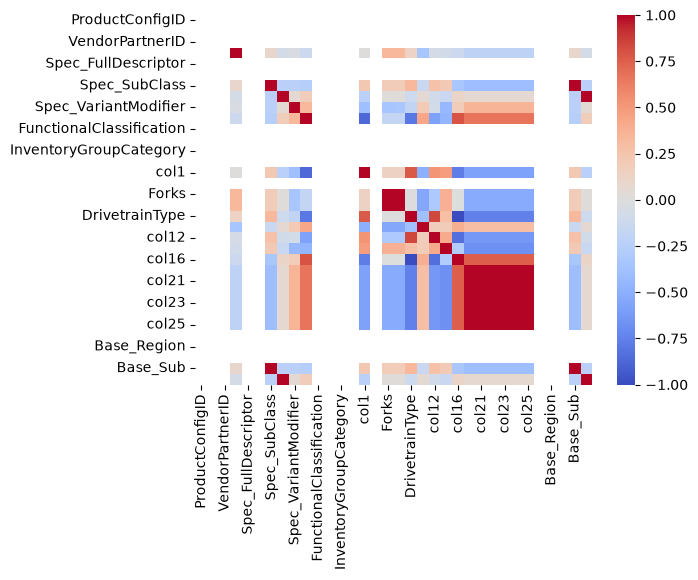

In [ ]:
df[cat_cols].isna().corr()
# let's create a heatman to better visualise
sns.heatmap(df[cat_cols].isna().corr(), annot = False, cmap = "coolwarm") 

we found that:
- col20/22/24(/21/23/25) + col15 (moderate positive correlation with each other)
- col3 + col10 (correlate with each other)
when one fields are missing, the other tends to be present, and vice versa.

In [ ]:
for i in ['col3', 'col10', 'col15', 'col20', 'Spec_ReleaseSeries', 'AssetScaleFactor']:
    print(i)
    print(train.groupby('InventoryGroupCategory')[i].apply(lambda x: x.isna().mean()))
    print()

col3
InventoryGroupCategory
BL     0.0
MG     1.0
SSL    1.0
TEX    1.0
TTT    1.0
WL     0.0
Name: col3, dtype: float64

col10
InventoryGroupCategory
BL     1.0
MG     0.0
SSL    0.0
TEX    0.0
TTT    0.0
WL     0.0
Name: col10, dtype: float64

col15
InventoryGroupCategory
BL     1.0
MG     0.0
SSL    1.0
TEX    1.0
TTT    1.0
WL     0.0
Name: col15, dtype: float64

col20
InventoryGroupCategory
BL     1.000000
MG     1.000000
SSL    1.000000
TEX    0.000028
TTT    1.000000
WL     1.000000
Name: col20, dtype: float64

Spec_ReleaseSeries
InventoryGroupCategory
BL     0.844813
MG     0.981671
SSL    0.030303
TEX    0.736729
TTT    0.578648
WL     0.693090
Name: Spec_ReleaseSeries, dtype: float64

AssetScaleFactor
InventoryGroupCategory
BL     1.000000
MG     1.000000
SSL    1.000000
TEX    0.000197
TTT    0.306438
WL     0.146248
Name: AssetScaleFactor, dtype: float64



#### saparating the columns into 2 types one with low cardinality and the other with high cardinality

In [ ]:
cat1_cols = [i for i in df[cat_cols].columns if df[i].nunique() <= 20]
cat2_cols = [i for i in df[cat_cols].columns if df[i].nunique() > 20]

[i for i in num_cols+cat1_cols+cat2_cols if i not in df.columns.to_list()]

[]

In [ ]:
len(num_cols+cat1_cols+cat2_cols), len(df.columns.to_list()) #these are na "TargetValue", "is_train"

(43, 45)

#### df -> train + test back

In [ ]:
train_df = df[df["is_train"]==1].drop(['is_train'], axis = 1).copy()
test_df = df[df["is_train"]==0].drop(['is_train', 'TargetValue'], axis = 1).copy()

In [ ]:
train.shape, train_df.shape, test.shape, test_df.shape

((138701, 51), (138701, 44), (15000, 50), (15000, 43))

## Data Preprocessing

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, TargetEncoder, RobustScaler
from sklearn.impute import SimpleImputer


num_pipe = Pipeline([
    ('impute', SimpleImputer(strategy='median', add_indicator=True)),  
    ('scale', RobustScaler()),
])

cat1_pipe = Pipeline([
    ('impute', SimpleImputer(strategy='constant', fill_value='Missing')),
    ('encode', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
])

cat2_pipe = Pipeline([
    ('impute', SimpleImputer(strategy='constant', fill_value='Missing')),
    ('encode', TargetEncoder(target_type='continuous')),  
    ('scale', RobustScaler()),
])

In [ ]:
# print("These are all the cat cols:", cat_cols)

In [ ]:
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer([
    ('num', num_pipe, num_cols),
    ('low_card', cat1_pipe, cat1_cols),
    ('high_card', cat2_pipe, cat2_cols),
], remainder='drop')

In [ ]:
from sklearn.model_selection import train_test_split
X = train_df.drop(['TargetValue'], axis = 1)
y = np.log1p(train_df['TargetValue'])
X_train, X_val, y_train, y_val = train_test_split(
    X, 
    y, 
    test_size=0.2, 
    random_state=42
)
X_test = test_df.copy(deep=True)

In [ ]:
X_train["AgeBucket"], age_bins = pd.qcut(X_train["AssetAge"], q =5, duplicates="drop", retbins=True)
X_val["AgeBucket"] = pd.cut(X_val["AssetAge"],bins=age_bins,include_lowest=True)
X_test["AgeBucket"] = pd.cut(X_test["AssetAge"],bins=age_bins,include_lowest=True)

In [ ]:
# age_bins

In [ ]:
# X_train_fnl= preprocessor.fit_transform(X_train, y_train)
# X_val_fnl = preprocessor.transform(X_val)
# X_test_fnl = preprocessor.transform(test_df)

In [ ]:
# preprocessor

In [ ]:
# drop_model_cols = ["TransactionID", "AssetID"]
for d in [X_train, X_val, X_test]:
    d["OperationalHoursMeter_missing"] = d["OperationalHoursMeter"].isna().astype(int)

In [ ]:
product_freq = X_train["ProductConfigID"].value_counts()
vendor_freq = X_train["VendorPartnerID"].value_counts()
baseclass_freq = X_train["Spec_BaseClass"].value_counts()
region_freq = X_train["RegionCode"].value_counts()
func_freq = X_train["FunctionalClassification"].value_counts()

for d in [X_train, X_val, X_test]:
    d["ProductFreq"] = d["ProductConfigID"].map(product_freq).fillna(0)
    d["VendorFreq"] = d["VendorPartnerID"].map(vendor_freq).fillna(0)
    d["BaseClassFreq"] = d["Spec_BaseClass"].map(baseclass_freq).fillna(0)
    d["RegionFreq"] = d["RegionCode"].map(region_freq).fillna(0)
    d["FuncFreq"] = d["FunctionalClassification"].map(func_freq).fillna(0)

In [ ]:
# by base class + age bucket
train_expected = (X_train.groupby(["Spec_BaseClass", "AgeBucket"], observed=True)["OperationalHoursMeter"].median().replace(0, np.nan))

for d in [X_train, X_val, X_test]:
    idx = d.set_index(["Spec_BaseClass", "AgeBucket"]).index
    expected = idx.map(train_expected)
    d["UsageRatio"] = d["OperationalHoursMeter"] / expected
    d["UsageRatio"] = d["UsageRatio"].replace([np.inf, -np.inf], np.nan).fillna(1.0)

In [ ]:
base_hours_median = (
    X_train.groupby("Spec_BaseClass", observed=True)["OperationalHoursMeter"]
    .median()
    .replace(0, np.nan)
)

global_hours_median = X_train["OperationalHoursMeter"].median()

for d in [X_train, X_val, X_test]:
    expected_base = d["Spec_BaseClass"].map(base_hours_median).fillna(global_hours_median)
    d["Hours_vs_BaseMedian"] = d["OperationalHoursMeter"] / expected_base
    d["Hours_vs_BaseMedian"] = d["Hours_vs_BaseMedian"].replace([np.inf, -np.inf], np.nan).fillna(1.0)

In [ ]:
X_train.dtypes

ProductConfigID                    object
DataOriginCode                        str
VendorPartnerID                       str
ManufactureYear                   float64
OperationalHoursMeter             float64
UtilizationTier                       str
Spec_FullDescriptor                   str
Spec_BaseClass                        str
Spec_SubClass                         str
Spec_ReleaseSeries                    str
Spec_VariantModifier                  str
AssetScaleFactor                      str
FunctionalClassification              str
RegionCode                            str
InventoryGroupCategory                str
InventoryGroupDescription             str
col1                                  str
CabinType                             str
Forks                                 str
col3                                  str
DrivetrainType                        str
col10                                 str
col12                                 str
col15                             

In [ ]:
cat_cols = X_train.select_dtypes(include=["object", "str", "category"]).columns.tolist()
num_cols = X_train.select_dtypes(include=["int", "float"]).columns.tolist()

for d in [X_train, X_val, X_test]:
    d[cat_cols] = d[cat_cols].astype(str).replace("nan", "Missing")

for d in [X_train, X_val, X_test]:
    d[cat_cols] = d[cat_cols].fillna("Missing").astype(str)
    for c in num_cols:
        d[c] = d[c].fillna(X_train[c].median())

In [ ]:
cat_features = X_train.select_dtypes(include="str").columns.tolist()
len(cat_features)

35

### Visualizing the data

In [ ]:
# %matplotlib inline
# for i in num_cols:
#     plt.title(f"{i} v/s frequency")
#     # print(i)
#     sns.histplot(data=train_df, x=i)
#     plt.show()

### Boxplots

In [ ]:
# %matplotlib inline
# for i in num_cols:
#     plt.title(f"{i} v/s frequency")
#     # print(i)
#     sns.boxplot(data=train_df, y=i)
#     plt.show()

## Model

In [ ]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
# from xgboost import XGBRegressor
# from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

models = {
    "baseline_median": DummyRegressor(strategy="median"),
    "linear_reg": LinearRegression(),
    "ridge": Ridge(alpha=1.0, random_state=42),
    "lasso": Lasso(alpha=0.01, random_state=42),
    "random_forest": RandomForestRegressor(n_estimators=300, max_depth=None, n_jobs=-1, random_state=42),
    "hist_gbm": HistGradientBoostingRegressor(random_state=42), 
    "catboost": CatBoostRegressor(iterations=500, learning_rate=0.05, depth=6, verbose=1, random_state=42),
}

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score 
results = []

# for name, model in models.items():
#     print(model, "----\n")

#     model.fit(X_train_fnl, y_train)
#     preds = model.predict(X_val_fnl)

#     results.append({
#         "Model": name,
#         "MAE": mean_absolute_error(y_val, preds),
#         "RMSE": np.sqrt(mean_squared_error(y_val, preds)),
#         "R2": r2_score(y_val, preds)
#     })

# results_df = (
#     pd.DataFrame(results).sort_values("RMSE").reset_index(drop=True)
# )


In [ ]:
# results_df

In [ ]:
# cat_model = CatBoostRegressor(
#     iterations=3500,
#     learning_rate=0.08,
#     depth=8,
#     l2_leaf_reg=5,
#     random_state=42,
#     verbose=5
# )

# cat_model.fit(
#     X_train,
#     y_train,
#     cat_features=cat_features,
#     eval_set=(X_val, y_val),
#     early_stopping_rounds=50
# )

# val_pred_log = cat_model.predict(X_val)
# val_rmse = np.sqrt(mean_squared_error(y_val, val_pred_log))
# print("Validation RMSE (log space):", val_rmse)

In [ ]:
pd.set_option('display.max_colwidth', None)

meta[["Variable","Rephrased Description"]]

,Variable,Rephrased Description
0,TransactionID,A unique serial number assigned to each individual accounting record.
1,TargetValue,"The financial amount of the transaction, denominated in US Dollars."
2,AssetID,The internal tracking number assigned to a specific piece of hardware.
3,ProductConfigID,A system-generated code representing the technical build-out of the unit.
4,DataOriginCode,A code indicating the specific software or platform where the data originated.
5,VendorPartnerID,The unique ID of the external entity or third-party provider involved.
6,TransactionDate,The official calendar date when the entry was finalized in the system.
7,RegionCode,The specific geographic area or legal jurisdiction where the event occurred.
8,ManufactureYear,The year the asset was originally produced.
9,OperationalHoursMeter,The lifetime total of active run-time or work cycles logged by the machine.


<Axes: >

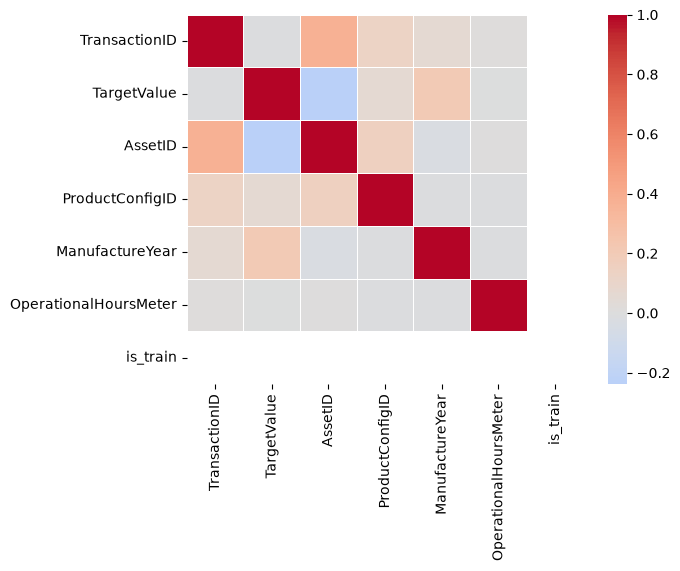

In [ ]:
num_col = train.select_dtypes(["int","float"]).columns

corr = train[num_col].corr()
# mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, fmt=".2f", cmap='coolwarm', center=0, linewidths=0.5)

In [ ]:
cat_cols = X_train.select_dtypes(include=["object", "str", "category"]).columns.tolist()

for d in [X_train, X_val, X_test]:
    d[cat_cols] = d[cat_cols].astype(str)

X_train.select_dtypes(include="str").columns.shape, X_train.shape

((35,), (110960, 52))

In [ ]:
import os
import joblib

# os.makedirs("models", exist_ok=True)
joblib.dump(cat_model, "catboost_v0.joblib")

In [ ]:
from lightgbm import LGBMRegressor
from sklearn.metrics import mean_squared_error
import numpy as np

X_train_lgb = X_train.copy()
X_val_lgb   = X_val.copy()
X_test_lgb  = X_test.copy()

drop_cols = ["TransactionID", "AssetID"]
for d in [X_train_lgb, X_val_lgb, X_test_lgb]:
    d.drop(columns=drop_cols, errors="ignore", inplace=True)

cat_cols = X_train_lgb.select_dtypes(include=["object", "category"]).columns.tolist()
num_cols = X_train_lgb.select_dtypes(include=["number"]).columns.tolist()

for d in [X_train_lgb, X_val_lgb, X_test_lgb]:
    d[cat_cols] = d[cat_cols].fillna("Missing").astype("category")
    for c in num_cols:
        d[c] = d[c].fillna(X_train_lgb[c].median())

lgb = LGBMRegressor(
    n_estimators=5000,
    learning_rate=0.02,
    num_leaves=128,
    subsample=0.8,
    colsample_bytree=0.8,
    device="cpu",
    n_jobs=-1,
    random_state=42
)

lgb.fit(
    X_train_lgb, y_train,
    eval_set=[(X_val_lgb, y_val)],
    eval_metric="rmse"
)

preds_lgb = lgb.predict(X_val_lgb)
rmse_lgb = np.sqrt(mean_squared_error(y_val, preds_lgb))
print(rmse_lgb)

/tmp/ipykernel_10319/250693037.py:13: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X_train_lgb.select_dtypes(include=["object", "category"]).columns.tolist()


[LightGBM] [Warning] Categorical features with more bins than the configured maximum bin number found.
[LightGBM] [Warning] For categorical features, max_bin and max_bin_by_feature may be ignored with a large number of categories.
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.011187 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 20938
[LightGBM] [Info] Number of data points in the train set: 110960, number of used features: 56
[LightGBM] [Info] Start training from score 10.424734
0.20615699647725652


In [ ]:
# from xgboost import XGBRegressor

# X_train_xgb = X_train.copy()
# X_val_xgb   = X_val.copy()
# X_test_xgb  = X_test.copy()
# # 
# for d in [X_train_xgb, X_val_xgb, X_test_xgb]:
#     d.drop(columns=drop_cols, errors="ignore", inplace=True)

# cat_cols = X_train_xgb.select_dtypes(include=["object", "category"]).columns.tolist()
# num_cols = X_train_xgb.select_dtypes(include=["number"]).columns.tolist()

# for d in [X_train_xgb, X_val_xgb, X_test_xgb]:
#     d[cat_cols] = d[cat_cols].fillna("Missing").astype("category")
#     for c in num_cols:
#         d[c] = d[c].fillna(X_train_xgb[c].median())


NameError: name 'drop_cols' is not defined

In [ ]:

# xgb = XGBRegressor(
#     n_estimators=5000,
#     learning_rate=0.03,
#     max_depth=8,
#     subsample=0.8,
#     colsample_bytree=0.8,
#     reg_lambda=1.0,
#     tree_method="hist",
#     enable_categorical=True,
#     random_state=42
# )

# xgb.fit(
#     X_train_xgb, y_train,
#     eval_set=[(X_val_xgb, y_val)],
#     verbose=200
# )

# preds_xgb = xgb.predict(X_val_xgb)
# rmse_xgb = np.sqrt(mean_squared_error(y_val, preds_xgb))
# print(rmse_xgb)

XGBoostError: [01:51:57] /__w/xgboost/xgboost/src/data/../data/cat_container.h:29: Found a category not in the training set for the 0th (0-based) column: `10218`
Stack trace:
  [bt] (0) /home/kradarsh/Desktop/ML_core/.venv/lib/python3.12/site-packages/xgboost/lib/libxgboost.so(+0x2c69bc) [0x716a3d2c69bc]
  [bt] (1) /home/kradarsh/Desktop/ML_core/.venv/lib/python3.12/site-packages/xgboost/lib/libxgboost.so(+0x63bf70) [0x716a3d63bf70]
  [bt] (2) /home/kradarsh/Desktop/ML_core/.venv/lib/python3.12/site-packages/xgboost/lib/libxgboost.so(+0x63c011) [0x716a3d63c011]
  [bt] (3) /home/kradarsh/Desktop/ML_core/.venv/lib/python3.12/site-packages/xgboost/lib/libxgboost.so(+0x65c749) [0x716a3d65c749]
  [bt] (4) /home/kradarsh/Desktop/ML_core/.venv/lib/python3.12/site-packages/xgboost/lib/libxgboost.so(+0x65f3e4) [0x716a3d65f3e4]
  [bt] (5) /home/kradarsh/Desktop/ML_core/.venv/lib/python3.12/site-packages/xgboost/lib/libxgboost.so(+0x6a606b) [0x716a3d6a606b]
  [bt] (6) /home/kradarsh/Desktop/ML_co

In [ ]:
cat_cols = X_train_xgb.select_dtypes(include=["category"]).columns.tolist()

print(cat_cols)
print(cat_cols[0])

['ProductConfigID', 'DataOriginCode', 'VendorPartnerID', 'UtilizationTier', 'Spec_FullDescriptor', 'Spec_BaseClass', 'Spec_SubClass', 'Spec_ReleaseSeries', 'Spec_VariantModifier', 'AssetScaleFactor', 'FunctionalClassification', 'RegionCode', 'InventoryGroupCategory', 'InventoryGroupDescription', 'col1', 'CabinType', 'Forks', 'col3', 'DrivetrainType', 'col10', 'col12', 'col15', 'col16', 'col20', 'col21', 'col22', 'col23', 'col24', 'col25', 'AgeBucket', 'Base_Function', 'Base_Region', 'Vendor_Product', 'Region_Function', 'Base_Sub', 'Base_Release']
ProductConfigID


In [ ]:
col = cat_cols[0]

train_vals = set(X_train_xgb[col].astype(str).unique())
val_vals   = set(X_val_xgb[col].astype(str).unique())

print("Unseen:", len(val_vals - train_vals))
print(list(val_vals - train_vals)[:20])

Unseen: 181
['22783', '3475', '6665', '22448', '18183', '17228', '17018', '22291', '8964', '299', '18920', '589', '17725', '6986', '17199', '26274', '9083', '5347', '14515', '15317']


In [ ]:
# X_train_cb = X_train.copy()
# X_val_cb = X_val.copy()
# X_test_cb = test_df.copy()

# for c in cat_cols:
#     X_train_cb[c] = X_train_cb[c].fillna('Missing').astype(str)
#     X_val_cb[c]   = X_val_cb[c].fillna('Missing').astype(str)
#     X_test_cb[c]  = X_test_cb[c].fillna('Missing').astype(str)
# for c in num_cols:
#     X_train_cb[c] = X_train_cb[c].fillna(X_train_cb[c].median())
#     X_val_cb[c]   = X_val_cb[c].fillna(X_train_cb[c].median())
#     X_test_cb[c]  = X_test_cb[c].fillna(X_train_cb[c].median())

# cb_native = CatBoostRegressor(iterations=3000, learning_rate=0.05, depth=10, l2_leaf_reg=3, random_state=42, verbose=1)
# cb_native.fit(X_train_cb, y_train, cat_features=cat_cols, eval_set=(X_val_cb, y_val), early_stopping_rounds=50)

In [ ]:
# for d in [8, 10]:
#     print(f"Training CatBoostRegressor with depth={d}")
#     m = CatBoostRegressor(iterations=3000, learning_rate=0.05, depth=d, l2_leaf_reg=3, random_state=42, verbose=1)
#     m.fit(X_train_cb, y_train, cat_features=cat_cols, eval_set=(X_val_cb, y_val), early_stopping_rounds=100)
    
#     print(d, m.get_best_score())

In [ ]:
import os
import joblib

# os.makedirs("models", exist_ok=True)
# joblib.dump(cat_model, "catboost_1.joblib")

In [ ]:
cat_model = joblib.load("catboost.joblib")

In [ ]:
fi = cat_model.get_feature_importance(prettified=True)
fi

,Feature Id,Importances
0,Func_AgeBucket_TE,15.074337
1,SalesYear,9.085367
2,Base_Sub,7.389993
3,AssetAge,4.988435
4,AgeBucket,4.049166
5,BaseClassFreq,3.862325
6,Spec_SubClass,3.623493
7,CabinType,3.459645
8,Trans_Month,3.207819
9,ManufactureYear,3.036034


In [ ]:
# dir(cat_model.feature_importances_)

In [ ]:
pd.s
meta

,Variable,Rephrased Description
0,TransactionID,A unique serial number assigned to each indivi...
1,TargetValue,"The financial amount of the transaction, denom..."
2,AssetID,The internal tracking number assigned to a spe...
3,ProductConfigID,A system-generated code representing the techn...
4,DataOriginCode,A code indicating the specific software or pla...
5,VendorPartnerID,The unique ID of the external entity or third-...
6,TransactionDate,The official calendar date when the entry was ...
7,RegionCode,The specific geographic area or legal jurisdic...
8,ManufactureYear,The year the asset was originally produced.
9,OperationalHoursMeter,The lifetime total of active run-time or work ...


### Residue Analysis

In [ ]:
preds = cat_model.predict(X_val)
residuals = np.expm1(y_val) - np.expm1(preds)

CatBoostError: Bad value for num_feature[non_default_doc_idx=0,feature_idx=38]="(10.0, 14.0]": Cannot convert '(10.0, 14.0]' to float

In [ ]:
residuals.sort_values(ascending=False).head(20)

NameError: name 'residuals' is not defined

In [ ]:
val_pred_log = cat_model.predict(X_val)
residual_log = y_val - val_pred_log
abs_resid_log = np.abs(residual_log)

In [ ]:
residual_log.describe()

count    27741.000000
mean        -0.001840
std          0.203278
min         -2.149429
25%         -0.108919
50%          0.001785
75%          0.111178
max          1.452403
Name: TargetValue, dtype: float64

In [ ]:
abs_resid_log.describe()

count    27741.000000
mean         0.146304
std          0.138101
min          0.000009
25%          0.050286
50%          0.108925
75%          0.199006
max          2.112736
Name: TargetValue, dtype: float64

In [ ]:
y_val_raw = np.expm1(y_val)
val_pred_raw = np.expm1(val_pred_log)

residual_raw = y_val_raw - val_pred_raw
abs_resid_raw = np.abs(residual_raw)

In [ ]:
residual_raw.describe()

count    27741.000000
mean       767.416075
std       7944.819923
min     -71143.158786
25%      -3202.324934
50%         84.839994
75%       4019.063807
max      81379.340308
Name: TargetValue, dtype: float64

In [ ]:
abs_resid_raw.describe()

count    27741.000000
mean      5394.774830
std       5882.556217
min          0.567536
25%       1550.002714
50%       3554.020650
75%       7215.159676
max      81379.340308
Name: TargetValue, dtype: float64

In [ ]:
X_train["AssetID"].shape

KeyError: 'AssetID'

In [ ]:
res_df = X_val_cb.copy()
res_df["y_true_log"] = y_val.values
res_df["y_pred_log"] = val_pred_log
res_df["residual_log"] = residual_log
res_df["abs_residual_log"] = abs_resid_log

res_df["y_true_raw"] = y_val_raw
res_df["y_pred_raw"] = val_pred_raw
res_df["residual_raw"] = residual_raw
res_df["abs_residual_raw"] = abs_resid_raw

res_df.sort_values("abs_residual_raw", ascending=False).head(20)

,TransactionID,AssetID,ProductConfigID,DataOriginCode,VendorPartnerID,ManufactureYear,OperationalHoursMeter,UtilizationTier,Spec_FullDescriptor,Spec_BaseClass,...,AssetAge,HoursPerYear,y_true_log,y_pred_log,residual_log,abs_residual_log,y_true_raw,y_pred_raw,residual_raw,abs_residual_raw
78741,2219060,46674,1595,CEA153,UNKNOWN_VENDOR,1994.0,10609.0,Medium,D5HIILGP,D5,...,15.0,707.266667,11.585255,10.158645,1.426610,1.426610,107500.0,25812.295992,81687.704008,81687.704008
116440,2567946,1260877,1609,FFA166,UJF,2006.0,0.0,Missing,D5NLGP,D5,...,5.0,0.000000,11.736077,10.765668,0.970409,0.970409,125000.0,47365.381838,77634.618162,77634.618162
111390,2454444,1779833,10481,CEA153,HCL,1999.0,0.0,Missing,EC290,EC290,...,8.0,318.200000,11.608245,10.493507,1.114737,1.114737,110000.0,36079.480670,73920.519330,73920.519330
37385,1486049,1516529,96,ADI149,MPF,1996.0,1600.0,Missing,966FII,966,...,4.0,318.200000,9.159152,11.256286,-2.097134,2.097134,9500.0,77363.726704,-67863.726704,67863.726704
60154,1687684,1517831,15153,ADI149,QUG,1996.0,1600.0,Missing,EX550LC,EX550,...,6.0,318.200000,9.239996,11.257664,-2.017668,2.017668,10300.0,77470.387897,-67170.387897,67170.387897
73864,1776990,1224971,30578,ADI149,UJF,2006.0,1600.0,Missing,GD6553VHP,GD655,...,5.0,318.200000,11.849405,11.206272,0.643133,0.643133,140000.0,73589.552232,66410.447768,66410.447768
70358,1761025,1440430,396,ADI149,IQP,2003.0,1600.0,Missing,PC200LC7,PC200,...,1.0,318.200000,10.146473,11.417936,-1.271463,1.271463,25500.0,90937.216446,-65437.216446,65437.216446
70356,1761023,1440430,396,ADI149,IQP,2003.0,1600.0,Missing,PC200LC7,PC200,...,1.0,318.200000,10.434145,11.498408,-1.064263,1.064263,34000.0,98557.779868,-64557.779868,64557.779868
79081,2221093,727441,96,CEA153,HCL,1999.0,0.0,Missing,966FII,966,...,11.0,0.000000,9.047939,11.197368,-2.149429,2.149429,8500.0,72937.230651,-64437.230651,64437.230651
87560,2264951,1673084,24297,CEA153,MPF,1999.0,0.0,Missing,D8RLRC,D8,...,12.0,0.000000,10.839601,11.601044,-0.761444,0.761444,51000.0,109210.785515,-58210.785515,58210.785515


In [ ]:
val_pred_log = cat_model.predict(X_val_cb)
residual_log = y_val - val_pred_log

res_df = X_val_cb.copy()
res_df["y_true_log"] = y_val.values
res_df["y_pred_log"] = val_pred_log
res_df["residual_log"] = residual_log
res_df["abs_residual_log"] = np.abs(residual_log)

res_df["y_true_raw"] = np.expm1(y_val)
res_df["y_pred_raw"] = np.expm1(val_pred_log)
res_df["residual_raw"] = res_df["y_true_raw"] - res_df["y_pred_raw"]
res_df["abs_residual_raw"] = np.abs(res_df["residual_raw"])

In [ ]:
display(res_df.groupby(pd.cut(res_df["AssetAge"], bins=[-np.inf, 0, 5, 10, 20, np.inf]))["abs_residual_log"].mean())
display(res_df.groupby("ProductConfigID")["abs_residual_log"].mean().sort_values(ascending=False).head(20))
display(res_df.groupby("FunctionalClassification")["abs_residual_log"].mean().sort_values(ascending=False).head(20))
display(res_df.groupby("RegionCode")["abs_residual_log"].mean().sort_values(ascending=False).head(20))

AssetAge
(-inf, 0.0]     0.137644
(0.0, 5.0]      0.116916
(5.0, 10.0]     0.158697
(10.0, 20.0]    0.158388
(20.0, inf]     0.164031
Name: abs_residual_log, dtype: float64

ProductConfigID
5353     1.452403
16442    1.433286
7088     1.315517
14287    1.132620
10481    1.114737
15153    1.105063
11651    1.043683
5272     0.962786
17592    0.925151
8415     0.909278
5238     0.907557
425      0.893953
22071    0.873494
13982    0.870246
16354    0.849547
15622    0.823901
16499    0.823725
620      0.815795
17070    0.811028
5341     0.803810
Name: abs_residual_log, dtype: float64

FunctionalClassification
Hydraulic Excavator, Track - Unidentified                     0.431729
Hydraulic Excavator, Track - 90.0 to 150.0 Metric Tons        0.382950
Hydraulic Excavator, Track - 66.0 to 90.0 Metric Tons         0.265612
Wheel Loader - 40.0 to 60.0 Horsepower                        0.235017
Wheel Loader - 350.0 to 500.0 Horsepower                      0.233951
Hydraulic Excavator, Track - 50.0 to 66.0 Metric Tons         0.230107
Wheel Loader - 500.0 to 1000.0 Horsepower                     0.221621
Motorgrader - 200.0 + Horsepower                              0.213196
Wheel Loader - 100.0 to 110.0 Horsepower                      0.204978
Hydraulic Excavator, Track - 4.0 to 6.0 Metric Tons           0.203239
Track Type Tractor, Dozer - 260.0 + Horsepower                0.196663
Hydraulic Excavator, Track - 40.0 to 50.0 Metric Tons         0.192341
Wheel Loader - 90.0 to 100.0 Horsepower                       0.187075
Hydraulic Excavator, Track - 150.0 to 300.0 Metric T

RegionCode
Hawaii           0.351081
Puerto Rico      0.297984
Alaska           0.208111
Montana          0.201969
South Dakota     0.179154
Kansas           0.176435
Washington       0.176023
Indiana          0.173961
Iowa             0.172203
Massachusetts    0.172134
Oklahoma         0.170654
Oregon           0.167934
Missouri         0.164753
Unspecified      0.162882
Minnesota        0.161878
North Dakota     0.161225
Ohio             0.161186
Nebraska         0.160234
Maine            0.159629
Illinois         0.159516
Name: abs_residual_log, dtype: float64

In [ ]:
preds = np.expm1(cb_native.predict(X_test_cb))

In [ ]:
submission = pd.DataFrame({
    'TransactionID': X_test_cb['TransactionID'],
    'TargetValue': preds
})
submission.to_csv('submission.csv', index=False)